# Step 8 — Model Validation and Reliability Analysis

## Objective

Steps 6 and 7 trained models for:
1. Broad material-category classification.
2. Product thermal-conductivity regression.

The initial results showed a large gap between validation and test performance. This notebook investigates where that gap comes from and whether the selected models behave consistently across material families.

We will:
- Reload the selected saved models and reports.
- Check the original grouped train/validation/test split.
- Compare material-family representation across splits.
- Evaluate classification performance by material family.
- Inspect classification confidence.
- Evaluate thermal-conductivity prediction errors by material family.
- Investigate whether missing input properties are related to prediction error.
- Produce a reliability summary.

**Important:** This is an evaluation experiment. It does not retrain or replace the selected models. It does not change the original dataset split.

## 1. Imports and locate the SpecSynth project

In [1]:
from pathlib import Path
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score,
    mean_absolute_error, mean_squared_error, r2_score
)

warnings.filterwarnings("ignore", category=FutureWarning)

DATASET_RELATIVE = Path(
    "04_Product_Dataset", "10_Master_Database",
    "SpecSynth_Master_Database_v1.0", "source_data", "v1.5.0"
)

def find_project_root(start=None):
    start = Path(start or Path.cwd()).resolve()
    for candidate in [start, *start.parents]:
        csv = candidate / DATASET_RELATIVE / "ml" / "SpecSynth_ML_variants_v1.5.0.csv"
        if csv.exists():
            return candidate
    fallback = Path(
        r"D:/02_LEARNING/02_Masters_IAAC_AI_Architecture/10-Term_01/"
        r"03-Research Studio/SpecSynth_AI"
    )
    if (fallback / DATASET_RELATIVE / "ml" / "SpecSynth_ML_variants_v1.5.0.csv").exists():
        return fallback
    raise FileNotFoundError(
        "Cannot locate SpecSynth_AI. Open this notebook inside the project "
        "or update the fallback path."
    )

PROJECT_ROOT = find_project_root()
ML_ROOT = PROJECT_ROOT / "06_AI_Performance_Engine" / "02_ML_Engine"
DATA_DIR = PROJECT_ROOT / DATASET_RELATIVE / "ml"
MODEL_DIR = ML_ROOT / "03_Models"
REPORT_DIR = ML_ROOT / "04_Evaluation" / "reports"

CSV_PATH = DATA_DIR / "SpecSynth_ML_variants_v1.5.0.csv"
df = pd.read_csv(CSV_PATH)

print("Project root:", PROJECT_ROOT)
print("Dataset shape:", df.shape)
print("Dataset version: v1.5.0")
display(df.head(3))

Project root: D:\02_LEARNING\02_Masters_IAAC_AI_Architecture\10-Term_01\03-Research Studio\SpecSynth_AI
Dataset shape: (1941, 47)
Dataset version: v1.5.0


,record_id,product_id,variant_id,material_category_group,material_family,category,manufacturer,market,record_origin,dataset_version_added,...,qa_flag_count,qa_flags,source_ids,split_group_id,target_thermal_conductivity_W_mK,target_density_kg_m3,target_specific_heat_J_kgK,target_gwp_a1_a3_kgco2e_m2,target_price_per_m2,recommended_split
0,ML_UNILIN_UTHERM_WALL_A_40MM,UNILIN_UTHERM_WALL_A,UNILIN_UTHERM_WALL_A_40MM,A_thermal_insulation,PIR,PIR insulation board,UNILIN Insulation,NaN,legacy_v1.2.0,1.2.0,...,0,NaN,SRC_UNILIN_DOP;SRC_UNILIN_TDS,UNILIN_UTHERM_WALL_A,0.022,32.0,NaN,NaN,NaN,train
1,ML_UNILIN_UTHERM_WALL_A_50MM,UNILIN_UTHERM_WALL_A,UNILIN_UTHERM_WALL_A_50MM,A_thermal_insulation,PIR,PIR insulation board,UNILIN Insulation,NaN,legacy_v1.2.0,1.2.0,...,0,NaN,SRC_UNILIN_DOP;SRC_UNILIN_TDS,UNILIN_UTHERM_WALL_A,0.022,32.0,NaN,NaN,NaN,train
2,ML_UNILIN_UTHERM_WALL_A_60MM,UNILIN_UTHERM_WALL_A,UNILIN_UTHERM_WALL_A_60MM,A_thermal_insulation,PIR,PIR insulation board,UNILIN Insulation,NaN,legacy_v1.2.0,1.2.0,...,0,NaN,SRC_UNILIN_DOP;SRC_UNILIN_TDS,UNILIN_UTHERM_WALL_A,0.022,32.0,NaN,NaN,NaN,train


### Outcome and conclusion

Confirm that the original v1.5.0 ML dataset is loaded. This notebook uses the saved models and the same dataset version used in the earlier experiments.

## 2. Load saved models and evaluation reports

In [2]:
classification_model_path = MODEL_DIR / "material_classification" / "best_material_classifier_v1.joblib"
classification_metrics_path = REPORT_DIR / "material_classification_metrics_v1.json"
classification_predictions_path = REPORT_DIR / "material_classification_test_predictions_v1.csv"

regression_model_path = MODEL_DIR / "thermal_prediction" / "thermal_conductivity_regressor_v1.joblib"
regression_metrics_path = REPORT_DIR / "thermal_regression_test_metrics_v1.json"

required_paths = [
    classification_model_path, classification_metrics_path,
    classification_predictions_path, regression_model_path,
    regression_metrics_path
]
missing_paths = [p for p in required_paths if not p.exists()]
if missing_paths:
    raise FileNotFoundError(
        "Some saved model/report files are missing. Run Steps 6 and 7 successfully first:\n" +
        "\n".join(str(p) for p in missing_paths)
    )

classification_model = joblib.load(classification_model_path)
classification_metrics = json.loads(classification_metrics_path.read_text(encoding="utf-8"))
classification_predictions_saved = pd.read_csv(classification_predictions_path)

regression_model = joblib.load(regression_model_path)
regression_metrics_summary = json.loads(regression_metrics_path.read_text(encoding="utf-8"))

print("Classification model:", classification_metrics.get("selected_model"))
print("Regression model:", regression_metrics_summary.get("selected_model"))
print("\nClassification test metrics from Step 6:")
display(pd.DataFrame([classification_metrics["test"]]))
print("\nRegression test metrics from Step 7:")
display(pd.DataFrame([regression_metrics_summary["test_metrics"]]))

Classification model: Extra Trees
Regression model: Extra Trees

Classification test metrics from Step 6:


,accuracy,balanced_accuracy,macro_f1
0,0.783582,0.804165,0.707828



Regression test metrics from Step 7:


,MAE_W_mK,RMSE_W_mK,R2
0,0.01275,0.034589,0.671823


### Outcome and conclusion

The selected classifiers and regressors are loaded from the model folders created in Steps 6 and 7. If a file is missing, stop and complete the earlier notebook rather than silently training a replacement model.

## 3. Check split integrity and group leakage

In [3]:
if "recommended_split" not in df.columns:
    raise KeyError("recommended_split is missing from the source dataset.")

split_counts = df["recommended_split"].astype(str).str.lower().value_counts().to_frame("records")
display(split_counts)

if "split_group_id" in df.columns:
    group_split_counts = df.groupby("split_group_id")["recommended_split"].nunique()
    leaking_groups = group_split_counts[group_split_counts > 1]
    print("Unique split groups:", df["split_group_id"].nunique())
    print("Groups appearing in more than one split:", len(leaking_groups))
    if len(leaking_groups):
        display(leaking_groups.head(20))
    else:
        print("No split_group_id appears across multiple splits.")
else:
    print("split_group_id is not present; group leakage cannot be checked from this file.")

if "material_family" in df.columns:
    family_split = pd.crosstab(
        df["material_family"],
        df["recommended_split"],
        normalize="columns"
    ) * 100
    display(family_split.round(1))

,records
recommended_split,
train,1621
validation,186
test,134


Unique split groups: 177
Groups appearing in more than one split: 0
No split_group_id appears across multiple splits.


recommended_split,test,train,validation
material_family,,,
AAC,0.0,1.0,2.2
CLT,20.1,0.0,0.0
EPS,0.0,22.6,0.0
Gypsum board,0.0,0.1,0.0
PF,0.0,1.5,0.0
PIR,0.0,8.6,25.8
PIR_sandwich_panel,33.6,1.1,0.0
PUR,0.0,1.5,0.0
PUR_sandwich_panel,0.0,0.9,0.0


### Outcome and conclusion

The original split should keep related product variants together. A group appearing in more than one split would be a serious concern because the model could see closely related records during training and then be tested on related variants.

The family distribution table also helps identify whether some material families are more common in one split than another. Differences in family representation can contribute to a validation/test performance gap.

## 4. Classification — reconstruct the original test split

### Feature-order correction

The saved classifier expects the exact feature names and order used during training. This section reads that information from the fitted model instead of independently recalculating feature order from the CSV. This prevents a feature-name/order mismatch.

In [4]:
target_candidates = [
    "material_category_group", "material_group",
    "category_group", "material_category"
]
CLASS_TARGET = next((c for c in target_candidates if c in df.columns), None)
if CLASS_TARGET is None:
    raise KeyError(
        "Could not identify the classification target. "
        f"Available columns: {df.columns.tolist()}"
    )

class_test = df[
    df["recommended_split"].astype(str).str.lower().eq("test")
].copy()

class_test[CLASS_TARGET] = class_test[CLASS_TARGET].astype("string").str.strip()
class_test = class_test[
    class_test[CLASS_TARGET].notna() & class_test[CLASS_TARGET].ne("")
].copy()

# IMPORTANT:
# Use the exact input feature names and order recorded by the fitted model.
# Recalculating feature columns from dataset coverage can produce a different
# order (or a different feature set) from the one used during Step 6 training.
if hasattr(classification_model, "feature_names_in_"):
    class_features = list(classification_model.feature_names_in_)
else:
    # Fallback for a Pipeline whose first preprocessing step stores feature names.
    class_features = None
    if hasattr(classification_model, "steps") and classification_model.steps:
        first_transformer = classification_model.steps[0][1]
        if hasattr(first_transformer, "feature_names_in_"):
            class_features = list(first_transformer.feature_names_in_)

if not class_features:
    raise AttributeError(
        "The saved classification model does not expose its fitted feature names. "
        "Please check the Step 6 model artifact and training notebook."
    )

missing_model_features = [c for c in class_features if c not in class_test.columns]
if missing_model_features:
    raise KeyError(
        "The source dataset is missing features required by the saved classifier: "
        f"{missing_model_features}"
    )

# Reindex enforces the exact feature order expected during model fitting.
X_class_test = (
    class_test.reindex(columns=class_features)
    .apply(pd.to_numeric, errors="coerce")
)
y_class_test = class_test[CLASS_TARGET].astype(str)

class_pred = classification_model.predict(X_class_test)

print("Classification target:", CLASS_TARGET)
print("Exact fitted feature order:", class_features)
print("Test records:", len(class_test))
print("Accuracy:", round(accuracy_score(y_class_test, class_pred), 4))
print("Balanced accuracy:", round(balanced_accuracy_score(y_class_test, class_pred), 4))
print("Macro F1:", round(f1_score(y_class_test, class_pred, average="macro", zero_division=0), 4))

Classification target: material_category_group
Exact fitted feature order: ['thickness_mm', 'thermal_resistance_m2K_W', 'thermal_conductivity_W_mK', 'compressive_strength_kPa', 'vapour_resistance_factor_mu', 'tensile_strength_perpendicular_kPa']
Test records: 134
Accuracy: 0.7836
Balanced accuracy: 0.8042
Macro F1: 0.7078


c:\Users\FawadSaleem\anaconda3\envs\arch_ai\Lib\site-packages\sklearn\metrics\_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


### Outcome and conclusion

This section independently reconstructs the original test partition and runs the saved classifier on it. Its overall metrics should be consistent with Step 6. If they differ, investigate differences in target selection, feature selection or dataset version before interpreting subgroup results.

## 5. Classification performance by material family

In [5]:
class_family_results = class_test[
    ["material_family"] if "material_family" in class_test.columns else []
].copy()
class_family_results["actual_group"] = y_class_test.to_numpy()
class_family_results["predicted_group"] = class_pred
class_family_results["correct"] = class_family_results["actual_group"] == class_family_results["predicted_group"]

family_class_rows = []
if "material_family" in class_family_results.columns:
    for family, part in class_family_results.groupby("material_family", dropna=False):
        family_class_rows.append({
            "material_family": family,
            "test_records": len(part),
            "accuracy": accuracy_score(part["actual_group"], part["predicted_group"]),
            "macro_f1": f1_score(
                part["actual_group"], part["predicted_group"],
                average="macro", zero_division=0
            ),
            "correct_records": int(part["correct"].sum())
        })

family_classification = pd.DataFrame(family_class_rows).sort_values(
    ["test_records", "accuracy"], ascending=[False, True]
)
display(family_classification.round(3))

,material_family,test_records,accuracy,macro_f1,correct_records
1,PIR_sandwich_panel,45,0.556,0.357,25
5,glass_wool,36,1.000,1.000,36
0,CLT,27,0.852,0.307,23
6,glazing_IGU,13,0.846,0.458,11
2,XPS,5,1.000,1.000,5
3,calcium_silicate_board,3,0.000,0.000,0
7,gypsum_board,2,1.000,1.000,2
8,gypsum_specialist_board,2,1.000,1.000,2
4,concrete_normal_weight,1,1.000,1.000,1


### Outcome and conclusion

This table shows whether the classifier works similarly across material families. Family-level scores based on very few test records are unstable, so always read the record count beside the score. A strong overall accuracy can hide weak performance in less-represented families.

## 6. Classification confidence analysis

,records,accuracy,average_confidence
confidence_band,,,
≤50%,19,0.789,0.416
50–70%,26,0.769,0.577
70–85%,32,0.625,0.784
>85%,57,0.877,0.904


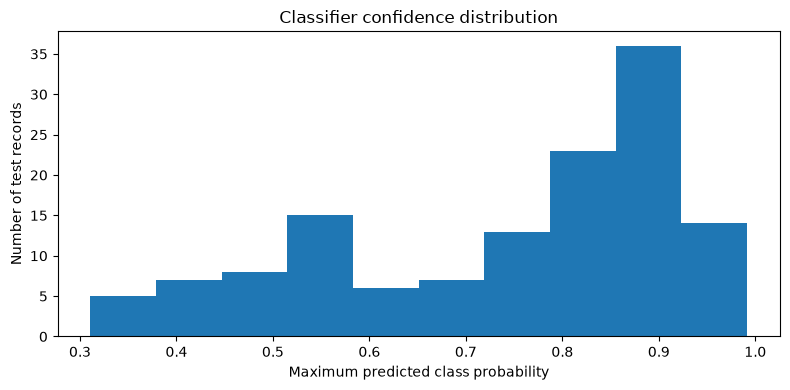

In [6]:
if hasattr(classification_model, "predict_proba"):
    class_probabilities = classification_model.predict_proba(X_class_test)
    confidence = class_probabilities.max(axis=1)

    confidence_df = pd.DataFrame({
        "actual_group": y_class_test.to_numpy(),
        "predicted_group": class_pred,
        "confidence": confidence,
        "correct": y_class_test.to_numpy() == class_pred
    })

    confidence_df["confidence_band"] = pd.cut(
        confidence_df["confidence"],
        bins=[0, 0.50, 0.70, 0.85, 1.000001],
        labels=["≤50%", "50–70%", "70–85%", ">85%"],
        include_lowest=True
    )

    confidence_summary = confidence_df.groupby(
        "confidence_band", observed=False
    ).agg(
        records=("correct", "size"),
        accuracy=("correct", "mean"),
        average_confidence=("confidence", "mean")
    )
    display(confidence_summary.round(3))

    plt.figure(figsize=(8, 4))
    plt.hist(confidence, bins=10)
    plt.xlabel("Maximum predicted class probability")
    plt.ylabel("Number of test records")
    plt.title("Classifier confidence distribution")
    plt.tight_layout()
    plt.show()
else:
    confidence_df = pd.DataFrame()
    confidence_summary = pd.DataFrame()
    print("Selected classifier does not expose predict_proba.")

### Outcome and conclusion

The confidence analysis checks whether high-confidence predictions are more often correct. A predicted probability is not automatically a calibrated probability of correctness. This analysis is a first reliability check, not a formal calibration study.

## 7. Regression — reconstruct the original test split

In [7]:
REG_TARGET = regression_metrics_summary["target"]
reg_features = regression_metrics_summary["features"]

reg_test = df[
    df["recommended_split"].astype(str).str.lower().eq("test")
].copy()

reg_test[REG_TARGET] = pd.to_numeric(reg_test[REG_TARGET], errors="coerce")
reg_test = reg_test[reg_test[REG_TARGET].notna()].copy()

X_reg_test = reg_test[reg_features].apply(pd.to_numeric, errors="coerce")
y_reg_test = reg_test[REG_TARGET].astype(float)
reg_pred = regression_model.predict(X_reg_test)

reg_test_results = reg_test[
    ["material_family"] if "material_family" in reg_test.columns else []
].copy()
reg_test_results["actual_W_mK"] = y_reg_test.to_numpy()
reg_test_results["predicted_W_mK"] = reg_pred
reg_test_results["error_W_mK"] = reg_pred - y_reg_test.to_numpy()
reg_test_results["absolute_error_W_mK"] = np.abs(reg_test_results["error_W_mK"])

overall_regression = {
    "test_records": len(reg_test_results),
    "MAE_W_mK": mean_absolute_error(y_reg_test, reg_pred),
    "RMSE_W_mK": np.sqrt(mean_squared_error(y_reg_test, reg_pred)),
    "R2": r2_score(y_reg_test, reg_pred)
}
display(pd.DataFrame([overall_regression]).round(5))

,test_records,MAE_W_mK,RMSE_W_mK,R2
0,114,0.01275,0.03459,0.67182


### Outcome and conclusion

The saved regression model is evaluated again on the original test records. The metrics should match Step 7. This independent reconstruction provides the record-level predictions needed for family and missingness analysis.

## 8. Regression error by material family

In [8]:
family_regression_rows = []
if "material_family" in reg_test_results.columns:
    for family, part in reg_test_results.groupby("material_family", dropna=False):
        family_regression_rows.append({
            "material_family": family,
            "test_records": len(part),
            "MAE_W_mK": mean_absolute_error(part["actual_W_mK"], part["predicted_W_mK"]),
            "RMSE_W_mK": np.sqrt(mean_squared_error(part["actual_W_mK"], part["predicted_W_mK"])),
            "mean_signed_error_W_mK": part["error_W_mK"].mean(),
            "median_absolute_error_W_mK": part["absolute_error_W_mK"].median()
        })

family_regression = pd.DataFrame(family_regression_rows).sort_values(
    ["test_records", "MAE_W_mK"], ascending=[False, False]
)
display(family_regression.round(5))

,material_family,test_records,MAE_W_mK,RMSE_W_mK,mean_signed_error_W_mK,median_absolute_error_W_mK
1,PIR_sandwich_panel,45,0.01048,0.01111,0.01048,0.01179
3,glass_wool,36,0.00274,0.00276,0.00268,0.00279
0,CLT,27,0.00524,0.00524,-0.00524,0.00524
2,calcium_silicate_board,3,0.13565,0.13565,-0.13565,0.13565
5,gypsum_specialist_board,2,0.16523,0.19313,-0.16523,0.16523
4,gypsum_board,1,0.00430,0.00430,0.00430,0.00430


### Outcome and conclusion

This table identifies material families where thermal-conductivity predictions have larger errors. The mean signed error indicates direction: positive means overprediction on average, negative means underprediction.

A family with only one or two test records cannot support a reliable performance claim. Treat small-family results as signals for further data collection.

## 9. Investigate missing input properties and prediction error

,missing_input_features,records,MAE_W_mK,median_absolute_error_W_mK,mean_signed_error_W_mK
0,2,5,0.00001,0.00000,0.00001
1,3,2,0.03478,0.03478,-0.03048
2,5,30,0.01828,0.00524,-0.01828
3,6,77,0.01085,0.01179,0.00393


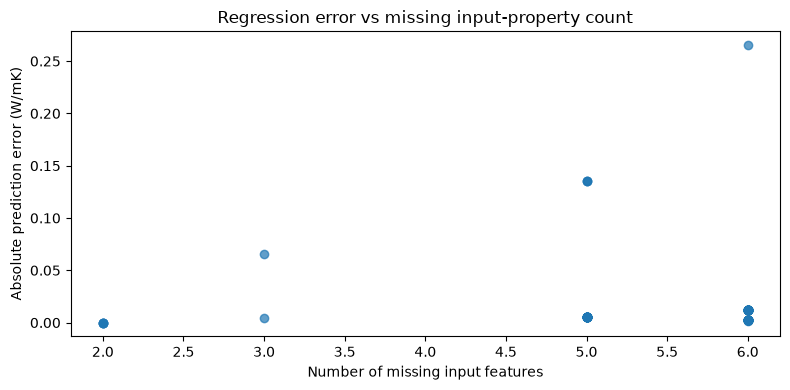

In [9]:
reg_missing_count = X_reg_test.isna().sum(axis=1)
missingness_analysis = reg_test_results.copy()
missingness_analysis["missing_input_features"] = reg_missing_count.to_numpy()

missingness_summary = missingness_analysis.groupby(
    "missing_input_features"
).agg(
    records=("absolute_error_W_mK", "size"),
    MAE_W_mK=("absolute_error_W_mK", "mean"),
    median_absolute_error_W_mK=("absolute_error_W_mK", "median"),
    mean_signed_error_W_mK=("error_W_mK", "mean")
).reset_index()

display(missingness_summary.round(5))

plt.figure(figsize=(8, 4))
plt.scatter(
    missingness_analysis["missing_input_features"],
    missingness_analysis["absolute_error_W_mK"],
    alpha=0.7
)
plt.xlabel("Number of missing input features")
plt.ylabel("Absolute prediction error (W/mK)")
plt.title("Regression error vs missing input-property count")
plt.tight_layout()
plt.show()

### Outcome and conclusion

This analysis checks whether records with more missing input properties tend to have larger prediction errors. A visible relationship would suggest that the model's reliability depends partly on how complete a product record is.

This is an association, not proof that missingness causes the error. Material family and target-value range may also influence the result.

## 10. Compare target distributions across splits

,records,mean,median,std,minimum,maximum
recommended_split,,,,,,
test,114,0.06080,0.032,0.06065,0.021,0.30
train,1493,0.03869,0.034,0.03058,0.020,0.35
validation,174,0.03552,0.032,0.02735,0.019,0.30


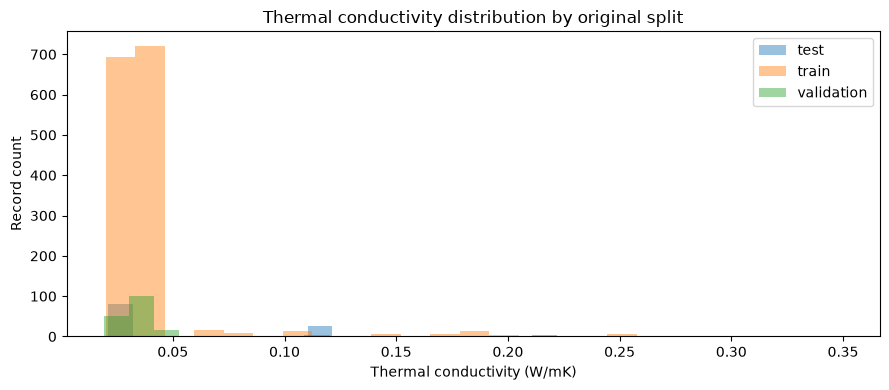

In [10]:
split_target = df.copy()
split_target[REG_TARGET] = pd.to_numeric(split_target[REG_TARGET], errors="coerce")
split_target = split_target.dropna(subset=[REG_TARGET])

target_summary = split_target.groupby("recommended_split")[REG_TARGET].agg(
    records="count",
    mean="mean",
    median="median",
    std="std",
    minimum="min",
    maximum="max"
)
display(target_summary.round(5))

plt.figure(figsize=(9, 4))
for split_name, part in split_target.groupby("recommended_split"):
    plt.hist(
        part[REG_TARGET],
        bins=25,
        alpha=0.45,
        label=str(split_name)
    )
plt.xlabel("Thermal conductivity (W/mK)")
plt.ylabel("Record count")
plt.title("Thermal conductivity distribution by original split")
plt.legend()
plt.tight_layout()
plt.show()

### Outcome and conclusion

If the test split contains a different conductivity range or family mix from training and validation, this can help explain weaker test performance. The split must not be changed just to improve the score; the difference should be documented and addressed through better representative data.

## 11. Build an overall reliability summary

In [11]:
classification_test_summary = {
    "accuracy": float(accuracy_score(y_class_test, class_pred)),
    "balanced_accuracy": float(balanced_accuracy_score(y_class_test, class_pred)),
    "macro_f1": float(f1_score(y_class_test, class_pred, average="macro", zero_division=0))
}

reliability_summary = {
    "dataset_version": "v1.5.0",
    "classification": {
        "selected_model": classification_metrics.get("selected_model"),
        "test_records": int(len(class_test)),
        "test_metrics_recalculated": classification_test_summary,
        "families_evaluated": int(family_classification.shape[0]),
        "lowest_family_accuracy": (
            float(family_classification["accuracy"].min())
            if len(family_classification) else None
        )
    },
    "thermal_conductivity_regression": {
        "selected_model": regression_metrics_summary.get("selected_model"),
        "test_metrics_recalculated": {
            k: float(v) for k, v in overall_regression.items()
            if k != "test_records"
        },
        "test_records": int(overall_regression["test_records"]),
        "families_evaluated": int(family_regression.shape[0]),
        "highest_family_MAE_W_mK": (
            float(family_regression["MAE_W_mK"].max())
            if len(family_regression) else None
        )
    },
    "split_integrity": {
        "group_column_available": "split_group_id" in df.columns,
        "groups_crossing_splits": (
            int((df.groupby("split_group_id")["recommended_split"].nunique() > 1).sum())
            if "split_group_id" in df.columns else None
        )
    },
    "interpretation_warning": (
        "Subgroup metrics are unstable for small family sample sizes. "
        "Classifier probabilities are not proven calibrated. "
        "Regression estimates do not replace manufacturer-declared values."
    )
}
display(pd.json_normalize(reliability_summary).T.rename(columns={0: "value"}))

c:\Users\FawadSaleem\anaconda3\envs\arch_ai\Lib\site-packages\sklearn\metrics\_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


,value
dataset_version,v1.5.0
interpretation_warning,Subgroup metrics are unstable for small family...
classification.selected_model,Extra Trees
classification.test_records,134
classification.test_metrics_recalculated.accuracy,0.783582
classification.test_metrics_recalculated.balanced_accuracy,0.804165
classification.test_metrics_recalculated.macro_f1,0.707828
classification.families_evaluated,9
classification.lowest_family_accuracy,0.0
thermal_conductivity_regression.selected_model,Extra Trees


### Outcome and conclusion

This summary collects the key reliability indicators from both models. Use it alongside the detailed tables rather than relying on one overall score.

## 12. Save validation and reliability reports

In [12]:
VALIDATION_REPORT_DIR = REPORT_DIR
VALIDATION_REPORT_DIR.mkdir(parents=True, exist_ok=True)

family_class_path = VALIDATION_REPORT_DIR / "classification_test_performance_by_family_v1.csv"
confidence_path = VALIDATION_REPORT_DIR / "classification_confidence_analysis_v1.csv"
family_reg_path = VALIDATION_REPORT_DIR / "thermal_regression_test_performance_by_family_v1.csv"
missingness_path = VALIDATION_REPORT_DIR / "thermal_regression_missingness_analysis_v1.csv"
reliability_path = VALIDATION_REPORT_DIR / "model_reliability_summary_v1.json"

family_classification.to_csv(family_class_path, index=False)
if not confidence_df.empty:
    confidence_df.to_csv(confidence_path, index=False)
family_regression.to_csv(family_reg_path, index=False)
missingness_analysis.to_csv(missingness_path, index=False)
reliability_path.write_text(json.dumps(reliability_summary, indent=2), encoding="utf-8")

print("Saved:", family_class_path)
print("Saved:", confidence_path if not confidence_df.empty else "No classifier confidence output")
print("Saved:", family_reg_path)
print("Saved:", missingness_path)
print("Saved:", reliability_path)

Saved: D:\02_LEARNING\02_Masters_IAAC_AI_Architecture\10-Term_01\03-Research Studio\SpecSynth_AI\06_AI_Performance_Engine\02_ML_Engine\04_Evaluation\reports\classification_test_performance_by_family_v1.csv
Saved: D:\02_LEARNING\02_Masters_IAAC_AI_Architecture\10-Term_01\03-Research Studio\SpecSynth_AI\06_AI_Performance_Engine\02_ML_Engine\04_Evaluation\reports\classification_confidence_analysis_v1.csv
Saved: D:\02_LEARNING\02_Masters_IAAC_AI_Architecture\10-Term_01\03-Research Studio\SpecSynth_AI\06_AI_Performance_Engine\02_ML_Engine\04_Evaluation\reports\thermal_regression_test_performance_by_family_v1.csv
Saved: D:\02_LEARNING\02_Masters_IAAC_AI_Architecture\10-Term_01\03-Research Studio\SpecSynth_AI\06_AI_Performance_Engine\02_ML_Engine\04_Evaluation\reports\thermal_regression_missingness_analysis_v1.csv
Saved: D:\02_LEARNING\02_Masters_IAAC_AI_Architecture\10-Term_01\03-Research Studio\SpecSynth_AI\06_AI_Performance_Engine\02_ML_Engine\04_Evaluation\reports\model_reliability_summar

### Outcome and conclusion

The notebook has saved family-level classification and regression reports, classifier confidence records, regression missingness analysis and a combined reliability summary. These reports provide evidence for deciding whether either model is suitable for further development.

# Final conclusion — Model Validation and Reliability Analysis

This experiment evaluates the saved material classifier and thermal-conductivity regressor beyond their overall scores.

It checks whether the original group-based split remains intact, whether material families are represented consistently across splits, and whether model performance changes across material families. It also investigates classifier confidence, regression errors and the relationship between missing input properties and prediction error.

The most important questions are:

1. Does the classifier perform consistently across material families, or is its overall score hiding weak categories?
2. Are high-confidence classification predictions more often correct?
3. Which material families have the largest thermal-conductivity prediction errors?
4. Do records with more missing input properties tend to have larger regression errors?
5. Does the test split have a different thermal-conductivity distribution from training and validation?

Do not interpret a family score based on only a few records as a stable performance estimate. Similarly, classifier probabilities are not proven calibrated simply because they are high.

**Final takeaway:** A model is not reliable just because it achieves a good overall score. It must also perform reasonably across relevant material families, unseen product groups and realistic levels of missing information. The outputs of this notebook will help determine whether the current models can proceed to production packaging or need further data and modelling work.

**Next action:** Run the notebook using the `arch_ai` kernel and upload the executed notebook. We will review the actual subgroup results and decide which models, if any, are ready for the next implementation stage.